# Example 5.3 — Hit expansion: from one screening hit to an SAR series

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-sonnet-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:55:48Z
- **Contents:** 1 exchange · 6 tool calls · 1 figure

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/` and the figures in `figures/`. With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/5.3-hit-expansion-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 5.3-hit-expansion-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 5.3-hit-expansion-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/5.3-hit-expansion-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 5.3-hit-expansion-notebook-rerun.ipynb 5.3-hit-expansion-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

I have a screening hit: Brc1cccc(Nc2ncnc3ccccc23)c1 — a 3-bromoanilino quinazoline. Find analogues, show the best ones, and tell me what the SAR suggests.

In [ ]:
# Call 1 · exact_structure_search · ran 2026-11-24 04:55:38 UTC
await replay.call(1, 'exact_structure_search', {'smiles': 'Brc1cccc(Nc2ncnc3ccccc23)c1'},
                  sha256='0164a704b7a49261a8204eaa89cf2b868be8dce943110977fac4c1acc17a09db')

**Call 1** · `exact_structure_search` · recorded result · sha256 `0164a704b7a4…`

| name | smiles |
| --- | --- |
| query | Brc1cccc(Nc2ncnc3ccccc23)c1 |

```json
{
  "query": {
    "input": "Brc1cccc(Nc2ncnc3ccccc23)c1",
    "canonical": "Brc1cccc(Nc2ncnc3ccccc23)c1",
    "inchi_key": "SUTRLYZWRGPLSJ-UHFFFAOYSA-N",
    "match": "same canonical isomeric SMILES (salts, stereo, charges and isotopes included)"
  },
  "n_exact_matches": 1
}
```

_1 row_

| monomerid | bdbm_id | name | smiles | mol_weight | n_activities | n_targets |
| --- | --- | --- | --- | --- | --- | --- |
| 3264 | BDBM3264 | 4-Anilino quinazoline deriv. 15 | Brc1cccc(Nc2ncnc3ccccc23)c1 | 299.01 | 5 | 2 |


In [ ]:
# Call 2 · find_targets_for_compound · ran 2026-11-24 04:55:38 UTC
await replay.call(2, 'find_targets_for_compound', {'monomerid': 3264, 'best_per_target': False},
                  sha256='80621965418fd64ea3d0e132eacb9396dc8d8ef5e36c039ffd97e850a64e2cc5')

**Call 2** · `find_targets_for_compound` · recorded result · sha256 `80621965418f…`

_5 rows_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 4853 | IC50 | = | 27 | nM | 7.57 | 3264 | 4-Anilino quinazoline deriv. 15 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens | 7.4 | 295.15 | Kinase Inhibition Assay | 7658435 | 10.1021/jm00018a008 | 1995 |
| 5269 | IC50 | = | 27 | nM | 7.57 | 3264 | 4-Anilino quinazoline deriv. 15 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens | 7.4 | 295.15 | Kinase Inhibition Assay | 8568816 | 10.1021/jm9503613 | 1996 |
| 50210589 | IC50 | = | 28 | nM | 7.55 | 3264 | 4-Anilino quinazoline deriv. 15 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_468986 (CHEMBL952131) | 18271520 | 10.1021/jm070654j | 2008 |
| 51085030 | IC50 | = | 1080 | nM | 5.97 | 3264 | 4-Anilino quinazoline deriv. 15 | 4026 |  | Broad substrate specificity ATP-binding cassette transporter ABCG2 | Q9UNQ0 | Homo sapiens |  |  | ChEMBL\_1278746 (CHEMBL3096293) | 24184213 | 10.1016/j.bmc.2013.10.007 | 2013 |
| 51085027 | IC50 | = | 1480 | nM | 5.83 | 3264 | 4-Anilino quinazoline deriv. 15 | 4026 |  | Broad substrate specificity ATP-binding cassette transporter ABCG2 | Q9UNQ0 | Homo sapiens |  |  | ChEMBL\_1278745 (CHEMBL3096292) | 24184213 | 10.1016/j.bmc.2013.10.007 | 2013 |


In [ ]:
# Call 3 · substructure_search · ran 2026-11-24 04:55:46 UTC
await replay.call(3, 'substructure_search', {'query': 'c1ccc(Nc2ncnc3ccccc23)cc1', 'count_only': True},
                  sha256='daa0e065dc7ccd03754365cd746656756433ebab0550ed2fd694807153d3d67c')

**Call 3** · `substructure_search` · recorded result · sha256 `daa0e065dc7c…`

| name | smiles |
| --- | --- |
| query | c1ccc(Nc2ncnc3ccccc23)cc1 |

```json
{
  "query": {
    "input": "c1ccc(Nc2ncnc3ccccc23)cc1",
    "interpreted_as": "smiles",
    "canonical": "c1ccc(Nc2ncnc3ccccc23)cc1"
  },
  "n_matching_compounds": 6323,
  "compounds_searched": 1466457,
  "compounds_indexed": 1466457
}
```


In [ ]:
# Call 4 · substructure_search · ran 2026-11-24 04:55:47 UTC
await replay.call(4, 'substructure_search', {'query': 'c1ccc(Nc2ncnc3ccccc23)cc1', 'summarize_by_target': True, 'limit': 10},
                  sha256='a49bf660c623a7c1c59f1dc8389d848943be5ddb9e8f107890d05042e9ca155d')

**Call 4** · `substructure_search` · recorded result · sha256 `a49bf660c623…`

| name | smiles |
| --- | --- |
| query | c1ccc(Nc2ncnc3ccccc23)cc1 |

```json
{
  "query": {
    "input": "c1ccc(Nc2ncnc3ccccc23)cc1",
    "interpreted_as": "smiles",
    "canonical": "c1ccc(Nc2ncnc3ccccc23)cc1"
  },
  "n_matching_compounds": 6323,
  "n_targets": 681,
  "n_compounds_measured": 6252,
  "compounds_searched": 1466457,
  "search_set_size": 1466457
}
```

_10 rows, truncated at the limit_

| target_kind | target_id | target_name | uniprot_raw | organism | n_compounds | n_measurements | affinity_types | best_p_affinity |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 520 | Epidermal growth factor receptor | P00533 | Homo sapiens | 2819 | 4689 | EC50, IC50, Kd, Ki | 11.52 |
| polymer | 692 | Vascular endothelial growth factor receptor 2 | P35968 | Homo sapiens | 1030 | 1242 | IC50, Kd | 9.22 |
| polymer | 188 | Receptor tyrosine-protein kinase erbB-2 | P04626 | Homo sapiens | 1023 | 1338 | EC50, IC50, Kd, Ki | 10.4 |
| polymer | 50000713 | Diacylglycerol kinase alpha | P23743 | Homo sapiens | 783 | 961 | IC50 | 9 |
| polymer | 5506 | MAP kinase-interacting serine/threonine-protein kinase 2 | Q9HBH9 | Homo sapiens | 509 | 812 | IC50, Kd | 9.1 |
| polymer | 50003028 | Ephrin type-A receptor 2 | P29317 | Homo sapiens | 303 | 364 | IC50, Kd | 7.3 |
| polymer | 5496 | Ephrin type-B receptor 4 | P54760 | Homo sapiens | 294 | 374 | IC50, Kd | 7.3 |
| polymer | 4026 | Broad substrate specificity ATP-binding cassette transporter ABCG2 | Q9UNQ0 | Homo sapiens | 230 | 429 | EC50, IC50, Ki | 9.22 |
| polymer | 10482 | Mast/stem cell growth factor receptor Kit \[544-976\] | P10721\[544-976\] | Homo sapiens | 212 | 213 | IC50 | 8 |
| polymer | 13 | Proto-oncogene tyrosine-protein kinase Src | P12931 | Homo sapiens | 174 | 219 | IC50, Kd | 9 |


In [ ]:
# Call 5 · substructure_search · ran 2026-11-24 04:55:47 UTC
await replay.call(5, 'substructure_search', {'query': 'c1ccc(Nc2ncnc3ccccc23)cc1', 'target_id': 520, 'max_value_nm': 10, 'limit': 15},
                  sha256='d66476feea65a1594d465995997f5086825d7c04f280d8f70977b37fe069171a')

**Call 5** · `substructure_search` · recorded result · sha256 `d66476feea65…`

| name | smiles |
| --- | --- |
| query | c1ccc(Nc2ncnc3ccccc23)cc1 |

```json
{
  "query": {
    "input": "c1ccc(Nc2ncnc3ccccc23)cc1",
    "interpreted_as": "smiles",
    "canonical": "c1ccc(Nc2ncnc3ccccc23)cc1"
  },
  "n_matching_compounds": 762,
  "compounds_searched": 3151,
  "search_set_size": 3151
}
```

_15 rows, truncated at the limit_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year | ligand_efficiency | lipe | pains_alerts | n_measurements | smiles |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 5350 | IC50 | = | 0.003 | nM | 11.52 | 3585 | Benzoquinazoline deriv. 23 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens | 7.4 | 295.15 | Kinase Inhibition Assay | 8632415 | 10.1021/jm950692f | 1996 | 0.72 | 6.23 |  | 1 | Brc1cccc(Nc2ncnc3cc4ccccc4cc23)c1 |
| 5321 | IC50 | = | 0.006 | nM | 11.22 | 3556 | PD153035 Analog | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | Kinase Inhibition Assay | 8568816 | 10.1021/jm9503613 | 1996 | 0.64 | 6.29 |  | 5 | CCOc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OCC |
| 50029862 | Ki | = | 0.006 | nM | 11.22 | 3032 | PD153035 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_473565 (CHEMBL940057) | 18077363 | 10.1073/pnas.0708800104 | 2007 | 0.7 | 7.07 |  | 17 | COc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OC |
| 5335 | IC50 | = | 0.008 | nM | 11.1 | 3570 | Anilinopyrimidine deriv. 7a | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens | 7.4 | 295.15 | Kinase Inhibition Assay | 8632415 | 10.1021/jm950692f | 1996 | 0.72 | 7.09 |  | 2 | Brc1cccc(Nc2ncnc3cc4nc\[nH\]c4cc23)c1 |
| 51613929 | IC50 | = | 0.009 | nM | 11.05 | 50651045 | CHEMBL5633067 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_2497198 | 37499291 | 10.1016/j.ejmech.2023.115671 |  | 0.47 | 8.03 |  | 6 | COCCOc1cc2ncnc(Nc3cccc(OS(=O)(=O)F)c3)c2cc1OCCOC |
| 5337 | IC50 | = | 0.01 | nM | 11 | 3572 | Imidazoquinazoline deriv. 10 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens | 7.4 | 295.15 | Kinase Inhibition Assay | 8632415 | 10.1021/jm950692f | 1996 | 0.69 | 6.98 |  | 1 | Cn1cnc2cc3ncnc(Nc4cccc(Br)c4)c3cc12 |
| 51352937 | IC50 | = | 0.01 | nM | 11 | 50322823 | AFATINIB | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_2017352 (CHEMBL4670930) | 32931277 | 10.1021/acs.jmedchem.0c00870 | 2020 | 0.44 | 6.61 |  | 102 | CN(C)C/C=C/C(=O)Nc1cc2c(cc1O\[C@H\]3CCOC3)ncnc2Nc4ccc(c(c4)Cl)F |
| 1057743 | IC50 | \< | 0.015 | nM | 10.82 | 504408 | US11040984, Compound 6 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | Kinase Assay | US11040984-B2 |  | 2021 | 0.44 | 5.57 |  | 1 | COc1cc2ncnc(Nc3ccc(Cl)c(Cl)c3F)c2cc1N1CC2(CCN(C)CC2)OC1=O |
| 1057749 | IC50 | \< | 0.015 | nM | 10.82 | 504412 | US11040984, Compound 18 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | Kinase Assay | US11040984-B2 |  | 2021 | 0.48 | 6.76 |  | 1 | COc1cc2ncnc(Nc3cccc(Cl)c3F)c2cc1N1C\[C@H\](CN(C)C)OC1=O \|r\| |
| 1057747 | IC50 | = | 0.016 | nM | 10.8 | 504411 | US11040984, Compound 13 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | Kinase Assay | US11040984-B2 |  | 2021 | 0.48 | 6.98 |  | 1 | COc1cc2ncnc(Nc3cccc(Cl)c3F)c2cc1N1CC2(CN(C)C2)OC1=O |
| 1057745 | IC50 | = | 0.017 | nM | 10.77 | 504410 | US11040984, Compound 12 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | Kinase Assay | US11040984-B2 |  | 2021 | 0.48 | 6.18 |  | 1 | CN1CCC2(CN(C(=O)O2)c2ccc3ncnc(Nc4cccc(Cl)c4F)c3c2)CC1 |
| 1057755 | IC50 | = | 0.021 | nM | 10.68 | 504415 | US11040984, Compound 30 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | Kinase Assay | US11040984-B2 |  | 2021 | 0.44 | 6.08 |  | 1 | CCCN1CC2(C1)CN(C(=O)O2)c1cc2c(Nc3cccc(Cl)c3F)ncnc2cc1OC |
| 1057753 | IC50 | = | 0.022 | nM | 10.66 | 504414 | US11040984, Compound 25 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | Kinase Assay | US11040984-B2 |  | 2021 | 0.46 | 6.45 |  | 1 | CCN1CC2(C1)CN(C(=O)O2)c1cc2c(Nc3cccc(Cl)c3F)ncnc2cc1OC |
| 5339 | IC50 | = | 0.025 | nM | 10.6 | 3574 | Imidazoquinazoline deriv. 12 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens | 7.4 | 295.15 | Kinase Inhibition Assay | 8632415 | 10.1021/jm950692f | 1996 | 0.66 | 6.58 |  | 1 | Cn1cnc2cc3c(Nc4cccc(Br)c4)ncnc3cc12 |
| 51525802 | IC50 | = | 0.027 | nM | 10.57 | 50613861 | CHEMBL5288888 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_2294498 | 36804726 | 10.1016/j.bmc.2023.117202 | 2023 | 0.4 | 5.68 |  | 4 | Fc1c(Cl)cccc1Nc1ncnc2cc(O\[C@H\]3CCOC3)c(OC3CCN(CC3)C(=O)C=C)cc12 \|r\| |


In [ ]:
# Call 6 · run_sql · ran 2026-11-24 04:55:47 UTC
sql = """
    SELECT a.source_id, a.year, a.monomerid, a.compound_name, a.affinity_type, a.relation, a.value, c.smiles FROM activity a JOIN compound c USING (monomerid) WHERE a.source_id IN ('7658435','8568816') AND a.polymerid = 520 AND a.affinity_type = 'IC50' ORDER BY a.value
    
"""
await replay.call(6, 'run_sql', {'sql': sql, 'max_rows': 200},
                  sha256='227e158f3ef4b27dea80a4c843e7673a174509b6038f1c172f16a59982279944')

**Call 6** · `run_sql` · recorded result · sha256 `227e158f3ef4…`

```json
{
  "order_warning": "Rows 4 and 5 tie on every ORDER BY column (value), so rows like them can swap places from run to run. End the ORDER BY with a unique column (e.g. monomerid; ki_result_id, affinity_type for measurements) so the result is the same on every run and a notebook's rerun check passes."
}
```

_118 rows_

| source_id | year | monomerid | compound_name | affinity_type | relation | value | smiles |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 8568816 | 1996 | 3556 | PD153035 Analog | IC50 | = | 0.006 | CCOc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OCC |
| 8568816 | 1996 | 3032 | PD153035 | IC50 | = | 0.025 | COc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OC |
| 8568816 | 1996 | 3568 | PD153035 Analog 68 | IC50 | = | 0.072 | COc1cc2ncnc(Nc3ccc(Br)c(Br)c3)c2cc1OC |
| 7658435 | 1995 | 3297 | 4-Anilinoquinazoline deriv. 48 | IC50 | = | 0.1 | Nc1ccc2c(Nc3cccc(Br)c3)ncnc2c1 |
| 8568816 | 1996 | 3297 | 4-Anilinoquinazoline deriv. 48 | IC50 | = | 0.1 | Nc1ccc2c(Nc3cccc(Br)c3)ncnc2c1 |
| 7658435 | 1995 | 3303 | 4-Anilinoquinazoline deriv. 54 | IC50 | = | 0.12 | Nc1cc2ncnc(Nc3cccc(Br)c3)c2cc1N |
| 8568816 | 1996 | 3303 | 4-Anilinoquinazoline deriv. 54 | IC50 | = | 0.12 | Nc1cc2ncnc(Nc3cccc(Br)c3)c2cc1N |
| 7658435 | 1995 | 3302 | 4-Anilinoquinazoline deriv. 53 | IC50 | = | 0.17 | Oc1cc2ncnc(Nc3cccc(Br)c3)c2cc1O |
| 8568816 | 1996 | 3302 | 4-Anilinoquinazoline deriv. 53 | IC50 | = | 0.17 | Oc1cc2ncnc(Nc3cccc(Br)c3)c2cc1O |
| 8568816 | 1996 | 3557 | PD153035 Analog 57 | IC50 | = | 0.17 | CCCOc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OCCC |
| 8568816 | 1996 | 3534 | PD153035 Analog 34 | IC50 | = | 0.24 | COc1cc2ncnc(Nc3cccc(c3)C(F)(F)F)c2cc1OC |
| 8568816 | 1996 | 3520 | PD153035 Analog 19 | IC50 | = | 0.25 | Nc1ccc2c(Nc3cccc(Cl)c3)ncnc2c1 |
| 8568816 | 1996 | 3532 | PD153035 Analog 31 | IC50 | = | 0.31 | COc1cc2c(cc1OC)ncnc2Nc3cccc(c3)Cl |
| 8568816 | 1996 | 3522 | PD153035 Analog 21 | IC50 | = | 0.35 | Nc1ccc2c(Nc3cccc(I)c3)ncnc2c1 |
| 8568816 | 1996 | 3564 | PD153035 Analog | IC50 | = | 0.67 | COc1cc2ncnc(Nc3cccc(Br)c3)c2c(OC)c1OC |
| 8568816 | 1996 | 3544 | PD153035 Analog 44 | IC50 | = | 0.69 | CNc1cc2ncnc(Nc3cccc(Br)c3)c2cc1N |
| 8568816 | 1996 | 3294 | Anilinoquinazoline, 4b | IC50 | = | 0.78 | Nc1ccc2ncnc(Nc3cccc(Br)c3)c2c1 |
| 7658435 | 1995 | 3294 | Anilinoquinazoline, 4b | IC50 | = | 0.79 | Nc1ccc2ncnc(Nc3cccc(Br)c3)c2c1 |
| 8568816 | 1996 | 3533 | PD153035 Analog 33 | IC50 | = | 0.89 | COc1cc2ncnc(Nc3cccc(I)c3)c2cc1OC |
| 8568816 | 1996 | 3567 | PD153035 Analog 67 | IC50 | = | 0.96 | COc1cc2ncnc(Nc3ccc(Br)cc3)c2cc1OC |
| 8568816 | 1996 | 3519 | PD153035 Analog 18 | IC50 | = | 2 | Nc1ccc2c(Nc3cccc(F)c3)ncnc2c1 |
| 8568816 | 1996 | 3523 | PD153035 Analog 22 | IC50 | = | 3.3 | Nc1ccc2c(Nc3cccc(c3)C(F)(F)F)ncnc2c1 |
| 8568816 | 1996 | 3531 | PD153035 Analog 30 | IC50 | = | 3.8 | COc1cc2ncnc(Nc3cccc(F)c3)c2cc1OC |
| 8568816 | 1996 | 3546 | PD153035 Analog 46 | IC50 | = | 3.8 | COc1cc2ncnc(Nc3cccc(Br)c3)c2cc1N |
| 8568816 | 1996 | 3535 | PD153035 Analog 35 | IC50 | = | 4 | CNc1ccc2ncnc(Nc3cccc(Br)c3)c2c1 |
| 8568816 | 1996 | 3538 | PD153035 Analog | IC50 | = | 4.7 | Oc1ccc2c(Nc3cccc(Br)c3)ncnc2c1 |
| 8568816 | 1996 | 3547 | PD153035 Analog 47 | IC50 | = | 6.5 | Nc1cc2c(Nc3cccc(Br)c3)ncnc2cc1Cl |
| 8568816 | 1996 | 3540 | PD153035 Analog | IC50 | = | 7 | CNc1ccc2c(Nc3cccc(Br)c3)ncnc2c1 |
| 7658435 | 1995 | 3289 | 4-(Benzylamino)quinazoline deriv. 40 | IC50 | = | 10 | COc1cc2ncnc(NCc3ccccc3)c2cc1OC |
| 8568816 | 1996 | 3298 | 4-Anilinoquinazoline deriv. 49 | IC50 | = | 10 | COc1ccc2c(Nc3cccc(Br)c3)ncnc2c1 |
| 7658435 | 1995 | 3298 | 4-Anilinoquinazoline deriv. 49 | IC50 | = | 10 | COc1ccc2c(Nc3cccc(Br)c3)ncnc2c1 |
| 8568816 | 1996 | 3542 | PD153035 Analog 42 | IC50 | = | 11 | CN(C)c1ccc2c(Nc3cccc(Br)c3)ncnc2c1 |
| 8568816 | 1996 | 3541 | PD153035 Analog 41 | IC50 | = | 12 | CCNc1ccc2c(Nc3cccc(Br)c3)ncnc2c1 |
| 8568816 | 1996 | 3537 | PD153035 Analog | IC50 | = | 12 | COC(=O)Nc1ccc2ncnc(Nc3cccc(Br)c3)c2c1 |
| 8568816 | 1996 | 3552 | PD153035 Analog 52 | IC50 | = | 15 | COc1cc2ncnc(Nc3cccc(Br)c3)c2cc1\[N+\](\[O-\])=O |
| 8568816 | 1996 | 3554 | PD153035 Analog 54 | IC50 | = | 15 | Brc1cccc(Nc2ncnc3cc4OCOc4cc23)c1 |
| 7658435 | 1995 | 3263 | 4-Anilino quinazoline deriv. 14 | IC50 | = | 23 | Clc1cccc(Nc2ncnc3ccccc23)c1 |
| 8568816 | 1996 | 3263 | 4-Anilino quinazoline deriv. 14 | IC50 | = | 23 | Clc1cccc(Nc2ncnc3ccccc23)c1 |
| 8568816 | 1996 | 3553 | PD153035 Analog | IC50 | = | 25 | \[O-\]\[N+\](=O)c1cc2c(Nc3cccc(Br)c3)ncnc2cc1Cl |
| 7658435 | 1995 | 3264 | 4-Anilino quinazoline deriv. 15 | IC50 | = | 27 | Brc1cccc(Nc2ncnc3ccccc23)c1 |
| 8568816 | 1996 | 3264 | 4-Anilino quinazoline deriv. 15 | IC50 | = | 27 | Brc1cccc(Nc2ncnc3ccccc23)c1 |
| 8568816 | 1996 | 3551 | PD153035 Analog 51 | IC50 | = | 28 | CC(=O)Nc1cc2ncnc(Nc3cccc(Br)c3)c2cc1\[N+\](\[O-\])=O |
| 8568816 | 1996 | 3530 | PD153035 Analog 29 | IC50 | = | 29 | COc1cc2ncnc(Nc3ccccc3)c2cc1OC |
| 8568816 | 1996 | 3295 | 4-Anilinoquinazoline deriv. 46 | IC50 | = | 30 | COc1ccc2ncnc(Nc3cccc(Br)c3)c2c1 |
| 8568816 | 1996 | 3539 | PD153035 Analog | IC50 | = | 40 | CC(=O)Nc1ccc2c(Nc3cccc(Br)c3)ncnc2c1 |
| 8568816 | 1996 | 3548 | PD153035 Analog | IC50 | = | 53 | Nc1cc2ncnc(Nc3cccc(Br)c3)c2cc1\[N+\](\[O-\])=O |
| 8568816 | 1996 | 3508 | PD153035 Analog 7 | IC50 | = | 55 | COc1ccc2ncnc(Nc3ccccc3)c2c1 |
| 8568816 | 1996 | 3503 | PD153035 Analog 2 | IC50 | = | 56 | Fc1cccc(Nc2ncnc3ccccc23)c1 |
| 7658435 | 1995 | 3288 | 4-(Benzylamino)quinazoline deriv. 39 | IC50 | = | 56 | COc1cc2ncnc(NCc3ccccc3)c2cc1O |
| 7658435 | 1995 | 3283 | 4-(Benzylamino)quinazoline deriv. 34 | IC50 | = | 58 | COc1ccc2c(NCc3ccccc3)ncnc2c1 |
| 8568816 | 1996 | 3549 | PD153035 Analog | IC50 | = | 68 | CNc1cc2ncnc(Nc3cccc(Br)c3)c2cc1\[N+\](\[O-\])=O |
| 7658435 | 1995 | 3265 | 4-Anilino quinazoline deriv. 16 | IC50 | = | 80 | Ic1cccc(Nc2ncnc3ccccc23)c1 |
| 8568816 | 1996 | 3265 | 4-Anilino quinazoline deriv. 16 | IC50 | = | 80 | Ic1cccc(Nc2ncnc3ccccc23)c1 |
| 8568816 | 1996 | 3536 | PD153035 Analog 36 | IC50 | = | 84 | CN(C)c1ccc2ncnc(Nc3cccc(Br)c3)c2c1 |
| 8568816 | 1996 | 3518 | PD153035 Analog 17 | IC50 | = | 100 | Nc1ccc2c(Nc3ccccc3)ncnc2c1 |
| 8568816 | 1996 | 3558 | PD153035 Analog 58 | IC50 | = | 105 | CCCCOc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OCCCC |
| 7658435 | 1995 | 3300 | 4-Anilinoquinazoline deriv. 51 | IC50 | = | 105 | Nc1cccc2c(Nc3cccc(Br)c3)ncnc12 |
| 8568816 | 1996 | 3569 | PD153035 Analog 69 | IC50 | = | 113 | COc1cc2ncnc(Nc3cc(Br)cc(Br)c3)c2cc1OC |
| 8568816 | 1996 | 3516 | PD153035 Analog 15 | IC50 | = | 120 | COc1ccc2c(Nc3ccccc3)ncnc2c1 |
| 8568816 | 1996 | 3566 | PD153035 Analog 66 | IC50 | = | 128 | COc1cc2ncnc(Nc3ccccc3Br)c2cc1OC |
| 7658435 | 1995 | 3292 | 4-Anilinoquinazoline deriv. 43 | IC50 | = | 139 | COc1cccc2ncnc(Nc3cccc(Br)c3)c12 |
| 8568816 | 1996 | 3563 | PD153035 Analog 63 | IC50 | = | 152 | COc1cc2ncnc(N(C)c3cccc(Br)c3)c2cc1OC |
| 8568816 | 1996 | 3545 | PD153035 Analog | IC50 | = | 159 | CN(C)c1cc2ncnc(Nc3cccc(Br)c3)c2cc1N |
| 7658435 | 1995 | 3280 | 4-(Benzylamino)quinazoline deriv. 31 | IC50 | = | 200 | COc1ccc2ncnc(NCc3ccccc3)c2c1 |
| 7658435 | 1995 | 3256 | N-benzylquinazolin-4-amine | IC50 | = | 320 | C(Nc1ncnc2ccccc12)c1ccccc1 |
| 7658435 | 1995 | 3259 | N-phenylquinazolin-4-amine | IC50 | = | 344 | N(c1ccccc1)c1ncnc2ccccc12 |
| 8568816 | 1996 | 3259 | N-phenylquinazolin-4-amine | IC50 | = | 344 | N(c1ccccc1)c1ncnc2ccccc12 |
| 7658435 | 1995 | 3295 | 4-Anilinoquinazoline deriv. 46 | IC50 | = | 348 | COc1ccc2ncnc(Nc3cccc(Br)c3)c2c1 |
| 7658435 | 1995 | 3290 | 4-Anilinoquinazoline deriv. 41 | IC50 | = | 355 | \[O-\]\[N+\](=O)c1cccc2ncnc(Nc3cccc(Br)c3)c12 |
| 7658435 | 1995 | 3291 | 4-Anilinoquinazoline deriv. 42 | IC50 | = | 439 | Nc1cccc2ncnc(Nc3cccc(Br)c3)c12 |
| 8568816 | 1996 | 3562 | PD153035 Analog | IC50 | = | 463 | COc1cc2nc(N)nc(Nc3cccc(Br)c3)c2cc1OC |
| 8568816 | 1996 | 3528 | PD153035 Analog 27 | IC50 | = | 540 | \[O-\]\[N+\](=O)c1ccc2c(Nc3cccc(I)c3)ncnc2c1 |
| 8568816 | 1996 | 3511 | PD153035 Analog 10 | IC50 | = | 574 | Nc1ccc2ncnc(Nc3cccc(c3)C(F)(F)F)c2c1 |
| 7658435 | 1995 | 3266 | 4-Anilino quinazoline deriv. 17 | IC50 | = | 577 | FC(F)(F)c1cccc(Nc2ncnc3ccccc23)c1 |
| 8568816 | 1996 | 3266 | 4-Anilino quinazoline deriv. 17 | IC50 | = | 577 | FC(F)(F)c1cccc(Nc2ncnc3ccccc23)c1 |
| 7658435 | 1995 | 3287 | 4-(Benzylamino)quinazoline deriv. 38 | IC50 | = | 588 | COc1cc2c(NCc3ccccc3)ncnc2cc1O |
| 7658435 | 1995 | 3268 | 4-(3-bromophenoxy)quinazoline | IC50 | = | 756 | Brc1cccc(Oc2ncnc3ccccc23)c1 |
| 8568816 | 1996 | 3510 | PD153035 Analog 9 | IC50 | = | 770 | Nc1ccc2ncnc(Nc3ccccc3)c2c1 |
| 8568816 | 1996 | 3526 | PD153035 Analog 25 | IC50 | = | 810 | \[O-\]\[N+\](=O)c1ccc2c(Nc3cccc(Cl)c3)ncnc2c1 |
| 7658435 | 1995 | 3261 | 4-Anilino quinazoline deriv. 12 | IC50 | = | 842 | COc1cccc(Nc2ncnc3ccccc23)c1 |
| 7658435 | 1995 | 3293 | 4-Anilinoquinazoline deriv. 44 | IC50 | = | 897 | \[O-\]\[N+\](=O)c1ccc2ncnc(Nc3cccc(Br)c3)c2c1 |
| 8568816 | 1996 | 3293 | 4-Anilinoquinazoline deriv. 44 | IC50 | = | 900 | \[O-\]\[N+\](=O)c1ccc2ncnc(Nc3cccc(Br)c3)c2c1 |
| 7658435 | 1995 | 3262 | 4-Anilino quinazoline deriv. 13 | IC50 | = | 910 | Cc1cccc(Nc2ncnc3ccccc23)c1 |
| 7658435 | 1995 | 3301 | 4-Anilinoquinazoline deriv. 52 | IC50 | = | 974 | COc1cccc2c(Nc3cccc(Br)c3)ncnc12 |
| 7658435 | 1995 | 3282 | 4-N-benzylquinazoline-4,7-diamine | IC50 | \> | 1000 | Nc1ccc2c(NCc3ccccc3)ncnc2c1 |
| 7658435 | 1995 | 3296 | 4-Anilinoquinazoline deriv. 47 | IC50 | = | 1000 | \[O-\]\[N+\](=O)c1ccc2c(Nc3cccc(Br)c3)ncnc2c1 |
| 7658435 | 1995 | 3267 | 4-Anilino quinazoline deriv. 18 | IC50 | \> | 1000 | N(c1cccnc1)c1ncnc2ccccc12 |
| 8568816 | 1996 | 3296 | 4-Anilinoquinazoline deriv. 47 | IC50 | = | 1000 | \[O-\]\[N+\](=O)c1ccc2c(Nc3cccc(Br)c3)ncnc2c1 |
| 7658435 | 1995 | 3274 | Benzotriazine deriv. 25 | IC50 | \> | 1000 | Brc1cccc(Nc2nnnc3ccccc23)c1 |
| 8568816 | 1996 | 3559 | PD153035 Analog 59 | IC50 | = | 1367 | COc1ccc2ncnc(Nc3cccc(Br)c3)c2c1OC |
| 7658435 | 1995 | 3279 | 4-N-benzylquinazoline-4,6-diamine | IC50 | = | 1400 | Nc1ccc2ncnc(NCc3ccccc3)c2c1 |
| 8568816 | 1996 | 3550 | PD153035 Analog | IC50 | = | 2000 | CN(C)c1cc2ncnc(Nc3cccc(Br)c3)c2cc1\[N+\](\[O-\])=O |
| 7658435 | 1995 | 3255 | 4-Anilino quinazoline deriv. 6 | IC50 | = | 4100 | c1ccc(cc1)CCNc2c3ccccc3ncn2 |
| 7658435 | 1995 | 3277 | 4-(Benzylamino)quinazoline deriv. 28 | IC50 | = | 4900 | COc1cccc2ncnc(NCc3ccccc3)c12 |
| 8568816 | 1996 | 3513 | PD153035 Analog 12 | IC50 | = | 5000 | \[O-\]\[N+\](=O)c1ccc2ncnc(Nc3ccccc3)c2c1 |
| 7658435 | 1995 | 3269 | quinoline deriv. 20 | IC50 | = | 5500 | Brc1cccc(Nc2ccnc3ccccc23)c1 |
| 7658435 | 1995 | 3281 | N-benzyl-7-nitroquinazolin-4-amine | IC50 | = | 5900 | \[O-\]\[N+\](=O)c1ccc2c(NCc3ccccc3)ncnc2c1 |
| 8568816 | 1996 | 3525 | PD153035 Analog 24 | IC50 | = | 6100 | \[O-\]\[N+\](=O)c1ccc2c(Nc3cccc(F)c3)ncnc2c1 |
| 7658435 | 1995 | 3257 | 4-(Benzylamino)quinazoline deriv. 8 | IC50 | = | 7000 | c1ccc2c(c1)c(ncn2)NCc3ccc(cc3)Cl |
| 7658435 | 1995 | 3275 | N-benzyl-5-nitroquinazolin-4-amine | IC50 | = | 8000 | \[O-\]\[N+\](=O)c1cccc2ncnc(NCc3ccccc3)c12 |
| 7658435 | 1995 | 3285 | 4-N-benzylquinazoline-4,8-diamine | IC50 | \> | 10000 | Nc1cccc2c(NCc3ccccc3)ncnc12 |
| 7658435 | 1995 | 3278 | N-benzyl-6-nitroquinazolin-4-amine | IC50 | \> | 10000 | \[O-\]\[N+\](=O)c1ccc2ncnc(NCc3ccccc3)c2c1 |
| 8568816 | 1996 | 3565 | PD153035 Analog 65 | IC50 | \> | 10000 | COc1cc2c(Nc3cccc(Br)c3)ncnc2c(OC)c1OC |
| 7658435 | 1995 | 3276 | 4-N-benzylquinazoline-4,5-diamine | IC50 | \> | 10000 | Nc1cccc2ncnc(NCc3ccccc3)c12 |
| 7658435 | 1995 | 3286 | 4-(Benzylamino)quinazoline deriv. 37 | IC50 | \> | 10000 | COc1cccc2c(NCc3ccccc3)ncnc12 |
| 7658435 | 1995 | 3271 | cinnoline deriv. 22 | IC50 | \> | 10000 | Brc1cccc(Nc2cnnc3ccccc23)c1 |
| 7658435 | 1995 | 3258 | 4-(Benzylamino)quinazoline deriv. 9 | IC50 | = | 10000 | COc1ccc(CNc2ncnc3ccccc23)cc1 |
| 8568816 | 1996 | 3529 | PD153035 Analog 28 | IC50 | \> | 10000 | \[O-\]\[N+\](=O)c1ccc2c(Nc3cccc(c3)C(F)(F)F)ncnc2c1 |
| 7658435 | 1995 | 3299 | 4-Anilinoquinazoline deriv. 50 | IC50 | \> | 10000 | \[O-\]\[N+\](=O)c1cccc2c(Nc3cccc(Br)c3)ncnc12 |
| 8568816 | 1996 | 3561 | PD153035 Analog | IC50 | \> | 10000 | COc1cc2nc(C)nc(Nc3cccc(Br)c3)c2cc1OC |
| 8568816 | 1996 | 3515 | PD153035 Analog 14 | IC50 | \> | 10000 | \[O-\]\[N+\](=O)c1ccc2ncnc(Nc3cccc(c3)C(F)(F)F)c2c1 |
| 8568816 | 1996 | 3560 | PD153035 Analog 60 | IC50 | \> | 10000 | COc1ccc2c(Nc3cccc(Br)c3)ncnc2c1OC |
| 7658435 | 1995 | 3284 | N-benzyl-8-nitroquinazolin-4-amine | IC50 | \> | 10000 | \[O-\]\[N+\](=O)c1cccc2c(NCc3ccccc3)ncnc12 |
| 8568816 | 1996 | 3524 | PD153035 Analog 23 | IC50 | = | 12000 | \[O-\]\[N+\](=O)c1ccc2c(Nc3ccccc3)ncnc2c1 |
| 7658435 | 1995 | 3273 | quinoxaline deriv. 24 | IC50 | \> | 100000 | Brc1cccc(Nc2cnc3ccccc3n2)c1 |
| 7658435 | 1995 | 3272 | phthalazine deriv. 23 | IC50 | \> | 100000 | Brc1cccc(Nc2nncc3ccccc23)c1 |
| 7658435 | 1995 | 3270 | isoquinoline deriv. 21 | IC50 | \> | 100000 | Brc1cccc(Nc2nccc3ccccc23)c1 |
| 7658435 | 1995 | 3260 | 4-Anilino quinazoline deriv. 11 | IC50 | = | 100000 | CN(c1ccccc1)c1ncnc2ccccc12 |


**Figure 1: SAR around a 4-anilinoquinazoline screening hit (EGFR).** _(as recorded)_

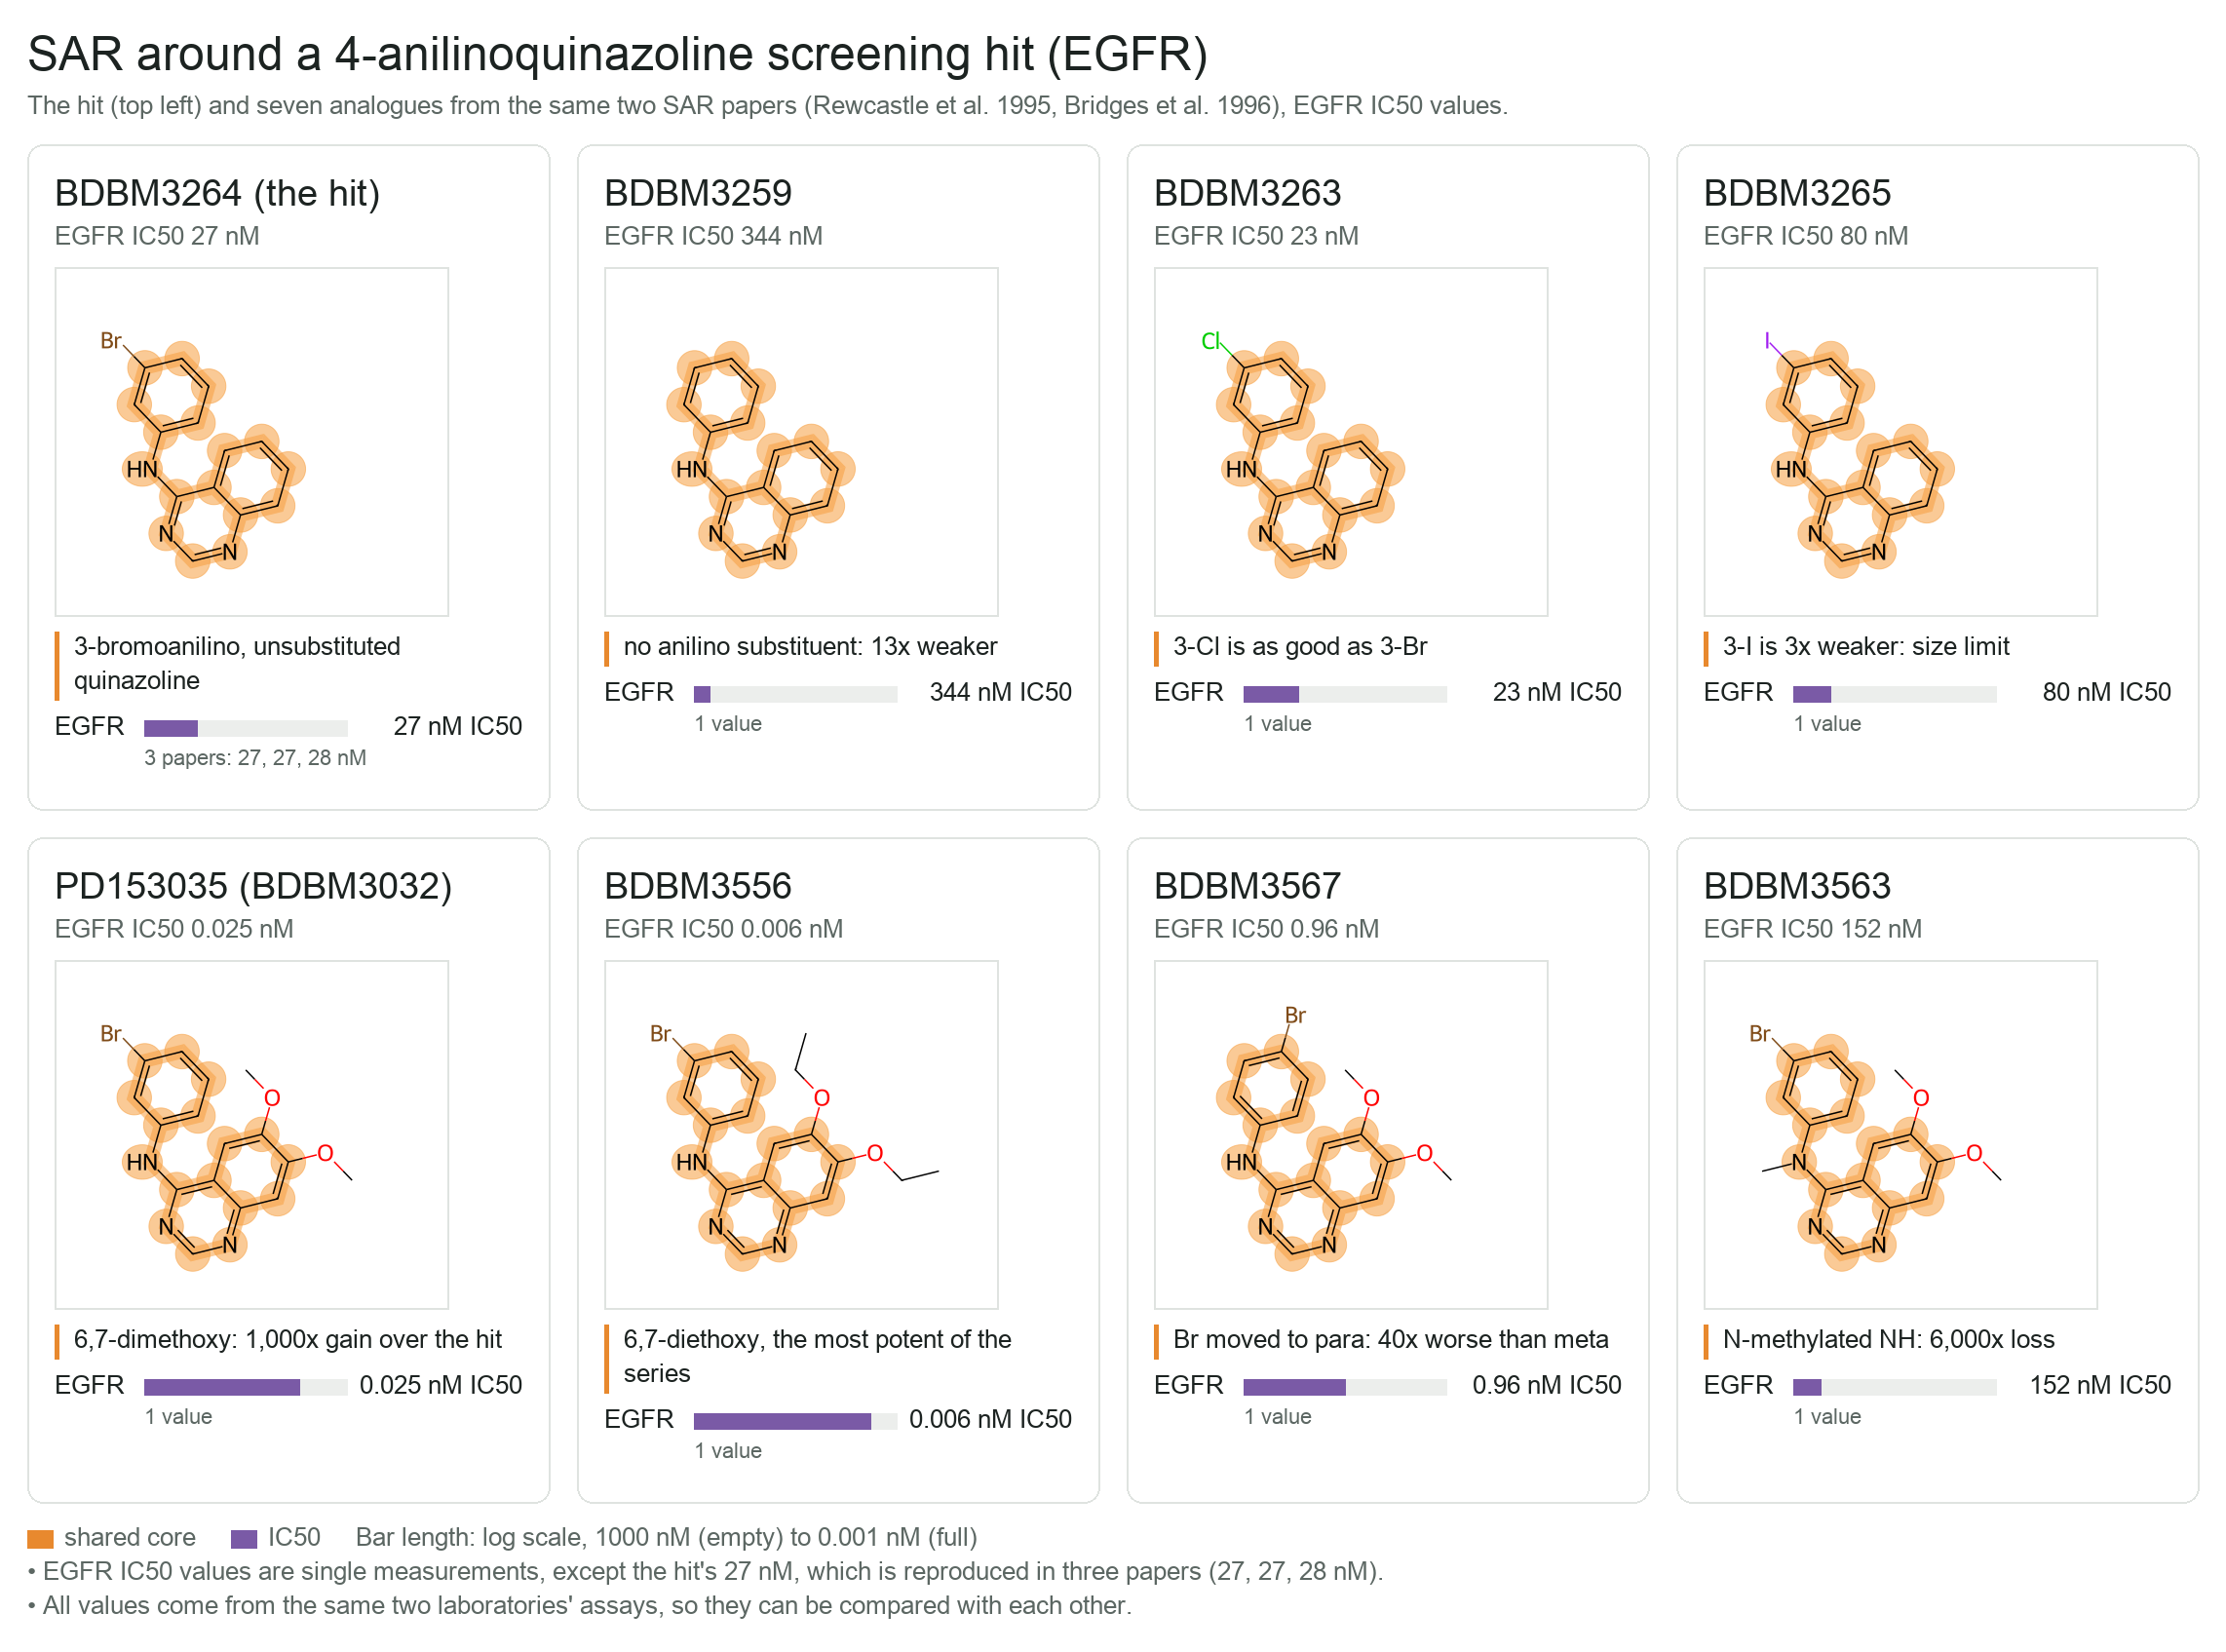

In [ ]:
# Figure 1 · draw_structure_grid draws it again
arguments = {
    'title': 'SAR around a 4-anilinoquinazoline screening hit (EGFR)',
    'compounds': [
        {
            'smiles': 'Brc1cccc(Nc2ncnc3ccccc23)c1',
            'title': 'BDBM3264 (the hit)',
            'subtitle': 'EGFR IC50 27 nM',
            'caption': '3-bromoanilino, unsubstituted quinazoline',
            'bars': [{'label': 'EGFR', 'value_nm': 27.0, 'type': 'IC50', 'note': '3 papers: 27, 27, 28 nM'}],
        },
        {
            'smiles': 'N(c1ccccc1)c1ncnc2ccccc12',
            'title': 'BDBM3259',
            'subtitle': 'EGFR IC50 344 nM',
            'caption': 'no anilino substituent: 13x weaker',
            'bars': [{'label': 'EGFR', 'value_nm': 344.0, 'type': 'IC50', 'note': '1 value'}],
        },
        {
            'smiles': 'Clc1cccc(Nc2ncnc3ccccc23)c1',
            'title': 'BDBM3263',
            'subtitle': 'EGFR IC50 23 nM',
            'caption': '3-Cl is as good as 3-Br',
            'bars': [{'label': 'EGFR', 'value_nm': 23.0, 'type': 'IC50', 'note': '1 value'}],
        },
        {
            'smiles': 'Ic1cccc(Nc2ncnc3ccccc23)c1',
            'title': 'BDBM3265',
            'subtitle': 'EGFR IC50 80 nM',
            'caption': '3-I is 3x weaker: size limit',
            'bars': [{'label': 'EGFR', 'value_nm': 80.0, 'type': 'IC50', 'note': '1 value'}],
        },
        {
            'smiles': 'COc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OC',
            'title': 'PD153035 (BDBM3032)',
            'subtitle': 'EGFR IC50 0.025 nM',
            'caption': '6,7-dimethoxy: 1,000x gain over the hit',
            'bars': [{'label': 'EGFR', 'value_nm': 0.025, 'type': 'IC50', 'note': '1 value'}],
        },
        {
            'smiles': 'CCOc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OCC',
            'title': 'BDBM3556',
            'subtitle': 'EGFR IC50 0.006 nM',
            'caption': '6,7-diethoxy, the most potent of the series',
            'bars': [{'label': 'EGFR', 'value_nm': 0.006, 'type': 'IC50', 'note': '1 value'}],
        },
        {
            'smiles': 'COc1cc2ncnc(Nc3ccc(Br)cc3)c2cc1OC',
            'title': 'BDBM3567',
            'subtitle': 'EGFR IC50 0.96 nM',
            'caption': 'Br moved to para: 40x worse than meta',
            'bars': [{'label': 'EGFR', 'value_nm': 0.96, 'type': 'IC50', 'note': '1 value'}],
        },
        {
            'smiles': 'COc1cc2ncnc(N(C)c3cccc(Br)c3)c2cc1OC',
            'title': 'BDBM3563',
            'subtitle': 'EGFR IC50 152 nM',
            'caption': 'N-methylated NH: 6,000x loss',
            'bars': [{'label': 'EGFR', 'value_nm': 152.0, 'type': 'IC50', 'note': '1 value'}],
        },
    ],
    'columns': 4,
    'description': 'The hit (top left) and seven analogues from the same two SAR papers (Rewcastle et al. 1995, Bridges et al. 1996), EGFR IC50 values.',
    'notes': [
        "EGFR IC50 values are single measurements, except the hit's 27 nM, which is reproduced in three papers (27, 27, 28 nM).",
        "All values come from the same two laboratories' assays, so they can be compared with each other.",
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(1, 'draw_structure_grid', arguments)

**🧠 Assistant**

**The hit itself is already in BindingDB.** An exact-structure search matched **BDBM3264** (named "4-Anilino quinazoline deriv. 15"), which has five measurements: **EGFR IC50 27 nM** in three separate papers (27, 27 and 28 nM; 1995, 1996 and 2008), plus two weak values on the ABCG2 transporter (1.1 and 1.5 uM, one 2013 paper). A hit that is already a known compound with reproduced data is the best possible starting point: the chemistry around it has been done.

**The scaffold is enormous.** The 4-anilinoquinazoline core (`c1ccc(Nc2ncnc3ccccc23)cc1`) matches **6,323 compounds** (6,252 of them with measurements), measured against 681 targets. The main ones:

| Target | Compounds | Measurements | Best pAffinity |
|---|---|---|---|
| EGFR (P00533) | 2,819 | 4,689 | 11.52 |
| VEGFR2 (P35968) | 1,030 | 1,242 | 9.22 |
| ERBB2 (P04626) | 1,023 | 1,338 | 10.40 |
| DGKA (P23743) | 783 | 961 | 9.00 |
| MKNK2 (Q9HBH9) | 509 | 812 | 9.10 |

So this is the EGFR inhibitor scaffold, with a wide spill-over onto other kinases and one lipid kinase (DGKA). 762 compounds on the scaffold have an EGFR value of 10 nM or better, and the best reach **IC50 0.003 nM**, about 9,000 times more potent than the hit. **Afatinib**, an approved drug, sits on the same core (EGFR IC50 0.01 nM).

**The SAR.** Rather than taking the most potent compounds from across 6,323 molecules, which would mix assays from hundreds of labs, I pulled the analogues measured **in the same two papers as the hit** (PMIDs 7658435 and 8568816, 118 EGFR IC50 values). That gives a clean congeneric series where the values can be compared directly. The figure below shows the hit with seven of them, aligned on the 17-atom 4-anilinoquinazoline core, which is highlighted. Three rules come out of it:

1. **Add 6,7-dialkoxy groups to the quinazoline: this is where the potency is.** 6,7-dimethoxy (PD153035) takes the hit from 27 nM to **0.025 nM**, a 1,000-fold gain; 6,7-diethoxy reaches 0.006 nM. Longer chains then lose it again (dipropoxy 0.17 nM, dibutoxy 105 nM), so there is a pocket with a size limit.
2. **Keep the halogen at the meta position.** 3-Br (27 nM) and 3-Cl (23 nM) are equivalent, 3-I is 3x weaker, 3-F is 2x weaker and no substituent is 13x weaker. Moving the same bromine to para costs 40x (0.025 to 0.96 nM) and to ortho costs 5,000x (128 nM).
3. **The anilino NH is essential.** Methylating it turns the 0.025 nM compound into a 152 nM one, a **6,000-fold loss**. That NH donates a hydrogen bond in the ATP site, and a single methyl group removes it.

**Lesson: for SAR, prefer one lab's series over the database's best values.** IC50 depends on ATP concentration, enzyme construct and readout, so values from different papers can differ by 10x for the same compound without either being wrong. Searching globally for "the most potent analogues" gives a list spanning dozens of assays, where real SAR and assay differences are impossible to separate. Filtering to a single source, as here, gives smaller numbers but trustworthy *ratios*. The database's broad view and a single paper's series answer different questions: the first says what is achievable on the scaffold, the second says what each change does.

**How this was answered**

- `exact_structure_search` with the hit's SMILES: confirmed it is BDBM3264 and already measured.
- `find_targets_for_compound` (`best_per_target=false`): showed all five of its measurements, which gave the reproduced 27 nM on EGFR.
- `substructure_search` with the core, `count_only=true` and then `summarize_by_target=true`: sized the scaffold (6,323 compounds) and found which targets it is used against.
- `substructure_search` with `target_id=520` (EGFR) and `max_value_nm=10`: found the most potent compounds on the scaffold, including afatinib.
- `run_sql` on `activity`: pulled every EGFR IC50 from the hit's own two source papers, which is the congeneric series the SAR rests on.
- `draw_structure_grid`: drew eight of them aligned on the shared core, with the core highlighted.

**Try next**

- "What else do the potent compounds on this scaffold hit besides EGFR?" (selectivity, Example 3.2)
- "Compare EGFR wild type and the T790M mutant for these compounds" (Example 3.3)

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 6 tool calls, 1 figure to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 5.3 — Hit expansion: from one screening hit to an SAR series, 2026-11-23, with claude-sonnet-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```